<h1><center> Agentic AI 2026/2027 (UvA - MSc AI) </center></h1>

<h2><center> Assignment 1 - Cooperation in the Coin Game </center></h2>


# 1. Introduction

In Lab 2, independent learners played the **Coin Game**, a grid world with a social dilemma: an agent that picks up a coin gets $+1$ whatever its colour, but if the coin has the *other* agent's colour, the other agent loses $2$. 

A Deep RL algorithm (PPO) solved the *generalization* problem of the game (it learned to ignore 8 irrelevant lamps that maded difficult learning with tabular methods), but not the *social dilemma*: tabular and deep learners alike stayed colour-blind, and the welfare stayed low. A better function approximator does not change the incentives.

In this assignment you will explore what a learning agent can do about cooperation, when it does not know its partner in advance. 

**Central questions:**
* *Can a learning agent sustain cooperation with partners it does not know, in a way that is good for both agents (welfare) and for itself (own reward)?*
* *And which choices of a learning agent (algorithm, training reward) matter?*

Please note: we suggest you first complete Lab 2. In Lecture 4 we will dive deeper into learning algorithms you can use (PPO, A2C, REINFORCE).

# 2. Your group task is to program the Blue agent

The Blue agent plays matches against Red agents whose policies and learning algorithms you do not know beforehand. Blue must be a **learning agent**. The complete assignment, including the report and the grading, is described in [Canvas](https://canvas.uva.nl/courses/59984/assignments/725263).

## 2.1 The environment

The Coin Game of Lab 2, on a larger grid, with a memory.

* A $6 \times 6$ grid on a **torus**: an agent that walks off one side enters on the opposite side.
* Actions: **0 = up, 1 = down, 2 = left, 3 = right**. Both agents move at the same time; they may share a cell.
* There is always exactly one coin, red or blue. When it is picked up (possibly by both agents in the same step), a new coin of random colour appears on a random free cell.
* An agent that picks up a coin receives $+1$, **whatever its colour**; if it is the *other* agent's coin, the other agent receives $-2$.
* An **episode** lasts 48 steps; then agents and coin are placed at random again.
* **Observations:** 116 numbers, representing: three $6 \times 6$ grids **centred on the agent itself** (the other agent, a coin of my colour, a coin of the other colour) and **8 history lamps**. Lamps 1-4 show the last 4 coins collected by **Red**, lamps 5-8 those collected by **Blue** (most recent first, the same order for both agents): **+1** if the collector took a coin of its *own* colour, **-1** if it took a coin of the *other's* colour, **0** if there is no pickup yet. A coin picked up by both agents in the same step is recorded for both.
* A **match** lasts 500 **updates**; one update is one episode in each of **8 parallel games**, after which learning agents update their policy. The lamps start at 0 at the beginning of a match and **carry over from one episode to the next** within the match. We consider that one update occurs after 8 parallel games to give each learning step more data (i.e., a batch of 384 decisions instead of 48), which makes gradients less noisy. 

## 2.2 Examples of Red agents

Your agent will be asked to perform well against a **pool** of five representative Red agents (their code is in Section 3.4):

| Red agent | what it does |
|---|---|
| **Greedy** | goes for every coin, whatever its colour, along a shortest path |
| **Altruist** | goes only for coins of its own colour; when the coin is Blue's, it moves at random, never onto the coin |
| **Reciprocator** | Before every step it looks at Blue's last 4 pickups (lamps 5-8). If any of them is $-1$ (Blue took a red coin), it plays **greedy** (it goes for every coin, blue ones included); otherwise it plays **altruist**. The agent turns **Altruist** again as soon as Blue's last 4 pickups contain no $-1$, i.e. after 4 further pickups of blue coins. |
| **Random** | moves at random |
| **PPO** | a PPO learner trained on its **own** reward; it starts from scratch in every match and learns during the match, just like your agent |


## 2.3 How an agent is evaluated: two scores

For every Red agent, a **fresh, untrained** Blue plays a match against a fresh Red. A match has **two scores**, both averaged over the **last 100 updates** of the match (both agents are then still learning and still sampling their actions, so the scores include their mistakes):

* the social **welfare**: Red's reward + Blue's reward per episode;
* Blue's **own reward** per episode.

The two scores are **never combined into one number**: maximising the welfare and maximising your own reward are different goals. Agents are compared on both at once, with a **Pareto plot**: an agent *dominates* another if it is at least as good on both scores and better on one. Where on this trade-off your agent should be is for you to choose and defend. The scores themselves are **not graded**; your reasoning and your evidence are.

## 2.4 Rules for your agent

1. Blue is a **learning agent**: it starts from scratch at the beginning of every match (no pre-trained weights, no files loaded) and learns during the match.
2. **No hand-coded action rules**: Blue's actions come from a policy that it learns. You may design its **training reward**, its learning algorithm, network and hyperparameters, and transformations of its observations (for example, features computed from the lamps).
3. Blue only uses its own **observations and rewards** (never the internal state of the environment or of Red). The helpers of the rule agents (`read_observations`, `torus_step`, `next_cell`, `torus_distance`) and the Red agents may not be used in your agent.
4. **Compute budget**: please note that we expect that a match of your agent against the PPO Red takes at most twice as long as a match of the default PPO Blue (about 30 s on a laptop).
5. Your agent is defined in the **single cell that starts with `# YOUR AGENT`** (Section 5.2).


# 3. Auxiliary code

**Run all cells of this section (about 10 seconds); do not modify them.** Section 4 describes the interface of meth. The code is documented for those who want to look inside.

| subsection | defines |
|---|---|
| 3.1 Setup and settings | `SEED`, `GRID_SIZE`, `EPISODE_LENGTH`, `HISTORY_LENGTH`, `N_ENVS`, `MATCH_UPDATES`, `SCORE_UPDATES`, `RED`, `BLUE` |
| 3.2 The environment | `CoinGame`, `play_episode`, `own_reward`, `RandomPolicy` |
| 3.3 Visualisation | `draw_coin_game`, `show_episode` |
| 3.4 Rule agents | `GreedyAgent`, `AltruistAgent`, `ReciprocatorAgent`  |
| 3.5 Learning agents | `PPOAgent`, `PPO_CONFIG`, `A2C_CONFIG`, `REINFORCE_CONFIG`, `welfare_reward`, `make_learner`, `DEV_POOL` |
| 3.6 Matches and evaluation | `play_match`, `match_score`, `evaluate_against_pool`, `print_results`, `plot_match`, `plot_pareto` |
| 3.7 Diagnostics | `reciprocity_curve`, `plot_reciprocity_curves`, `make_lamp_ablation`, `foreign_pickups_by_step` |

## 3.1 Setup and settings

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical

SEED = 42                    # fixed seed: every experiment is reproducible
torch.set_num_threads(1)    # small networks run faster on one CPU thread, and the results are more reproducible

GRID_SIZE = 6               # the grid has GRID_SIZE x GRID_SIZE cells, on a torus (leaving one side = entering the other)
EPISODE_LENGTH = 48         # steps per episode
HISTORY_LENGTH = 4          # lamps per agent: the colours of its last 4 pickups
N_ENVS = 8                  # parallel games in a match (relevant to compute less noisy gradients)
MATCH_UPDATES = 500         # updates (= episodes in every parallel game) in a match
SCORE_UPDATES = 100         # the scores of a match are averages over its last SCORE_UPDATES updates

MOVES = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]])     # (row change, column change) of up, down, left, right
ACTION_NAMES = ['up', 'down', 'left', 'right']
RED, BLUE = 0, 1
AGENT_NAMES = ['red', 'blue']

## 3.2 The environment

In [2]:
class CoinGame:
    """n_envs Coin Games played in parallel on a grid_size x grid_size torus, with history lamps.

    reset() starts a new episode in every game and returns the observations; step(actions) plays one step.
    The history lamps are kept across episodes and only cleared by start_match().

    Observations: a list [red_observations, blue_observations], each a float32 array of shape (n_envs, 116):
    3 egocentric grids [other agent, coin of my colour, coin of the other colour] (3 x 36 numbers), then the
    8 lamps [red's last 4 pickups, blue's last 4 pickups] (+1 own colour, -1 other's colour, 0 no pickup yet).
    """

    def __init__(self, n_envs, grid_size=GRID_SIZE, episode_length=EPISODE_LENGTH, seed=SEED):
        self.n_envs = n_envs
        self.grid_size = grid_size
        self.n_cells = grid_size * grid_size
        self.episode_length = episode_length
        self.n_inputs = 3 * self.n_cells + 2 * HISTORY_LENGTH
        self.rng = np.random.default_rng(seed)
        self.start_match()

    def start_match(self):
        """Clear the history lamps (at the start of a match)."""
        # history[env, agent, k] = +1 (own colour), -1 (other's colour) or 0 (no pickup yet); k = 0 is the most recent
        self.history = np.zeros((self.n_envs, 2, HISTORY_LENGTH), dtype=np.float32)

    def reset(self):
        """Start a new episode in every game (random positions, new coin); the history is kept. Returns the observations."""
        red_cell = self.rng.integers(self.n_cells, size=self.n_envs)
        blue_cell = (red_cell + self.rng.integers(1, self.n_cells, size=self.n_envs)) % self.n_cells
        self.agent_cells = np.stack([red_cell, blue_cell])          # shape (2, n_envs)
        self.coin_cell = np.zeros(self.n_envs, dtype=int)
        self.coin_colour = np.zeros(self.n_envs, dtype=int)
        self.place_new_coins(np.ones(self.n_envs, dtype=bool))
        self.t = 0
        return self.observations()

    def place_new_coins(self, needs_coin):
        """New coin (random colour) on a random cell not occupied by an agent, in the games where needs_coin is True."""
        envs = np.where(needs_coin)[0]
        cells = self.rng.integers(self.n_cells, size=len(envs))
        on_an_agent = (cells == self.agent_cells[0, envs]) | (cells == self.agent_cells[1, envs])
        while on_an_agent.any():
            cells[on_an_agent] = self.rng.integers(self.n_cells, size=on_an_agent.sum())
            on_an_agent = (cells == self.agent_cells[0, envs]) | (cells == self.agent_cells[1, envs])
        self.coin_cell[envs] = cells
        self.coin_colour[envs] = self.rng.integers(2, size=len(envs))

    def record_pickups(self, picked):
        """Shift the history of every agent that picked up the coin, and put the new pickup in front."""
        for agent in (RED, BLUE):
            envs = np.where(picked[agent])[0]
            lamp = np.where(self.coin_colour[envs] == agent, 1.0, -1.0)
            older_pickups = self.history[envs, agent, :-1].copy()
            self.history[envs, agent, 1:] = older_pickups
            self.history[envs, agent, 0] = lamp

    def step(self, actions):
        """Play one step. actions = [red actions, blue actions], each an int array of shape (n_envs,).

        Returns (observations, rewards, info): rewards is a float32 array of shape (2, n_envs) with rows [red, blue];
        info = {'picked': bool (2, n_envs), 'picked_own': bool (2, n_envs)}.
        """
        for agent in (RED, BLUE):
            row = self.agent_cells[agent] // self.grid_size
            column = self.agent_cells[agent] % self.grid_size
            row = (row + MOVES[actions[agent], 0]) % self.grid_size
            column = (column + MOVES[actions[agent], 1]) % self.grid_size
            self.agent_cells[agent] = row * self.grid_size + column

        picked = np.stack([self.agent_cells[agent] == self.coin_cell for agent in (RED, BLUE)])
        picked_own = np.stack([picked[agent] & (self.coin_colour == agent) for agent in (RED, BLUE)])
        rewards = np.zeros((2, self.n_envs), dtype=np.float32)
        for agent in (RED, BLUE):
            other = 1 - agent
            other_took_my_coin = picked[other] & (self.coin_colour == agent)
            rewards[agent] = 1.0 * picked[agent] - 2.0 * other_took_my_coin

        self.record_pickups(picked)
        self.place_new_coins(picked[RED] | picked[BLUE])
        self.t += 1
        info = {'picked': picked, 'picked_own': picked_own}
        return self.observations(), rewards, info

    def relative_cells(self, cells, agent):
        """Cells counted from the position of `agent` (egocentric view): the agent itself is at cell 0."""
        size = self.grid_size
        my_row = self.agent_cells[agent] // size
        my_column = self.agent_cells[agent] % size
        row = (cells // size - my_row) % size
        column = (cells % size - my_column) % size
        return row * size + column

    def observations(self):
        """[red_observations, blue_observations]: 3 egocentric grids and the 8 lamps per game (see the class docstring)."""
        all_envs = np.arange(self.n_envs)
        lamps = self.history.reshape(self.n_envs, 2 * HISTORY_LENGTH)       # red's 4 lamps, then blue's 4 lamps
        observations = []
        for agent in (RED, BLUE):
            grids = np.zeros((self.n_envs, 3, self.n_cells), dtype=np.float32)
            grids[all_envs, 0, self.relative_cells(self.agent_cells[1 - agent], agent)] = 1.0
            coin_channel = np.where(self.coin_colour == agent, 1, 2)
            grids[all_envs, coin_channel, self.relative_cells(self.coin_cell, agent)] = 1.0
            observations.append(np.concatenate([grids.reshape(self.n_envs, 3 * self.n_cells), lamps], axis=1))
        return observations

In [3]:
def own_reward(my_reward, other_reward, observations):
    """The default training reward: an agent learns from its own reward."""
    return my_reward


def play_episode(env, policies, learn=True):
    """Play one episode in every game of `env`. policies = [red, blue].

    Every policy needs act(observations) -> actions. A learning agent also has record(...) (called after every step)
    and end_of_episode(...) (called at the end); it learns from its training_reward(my_reward, other_reward,
    observations) if it has one, else from its own reward. All statistics use the environment's own rewards.

    Returns a dict of statistics per episode (averaged over the games): 'coins' (pickups, both agents),
    'own_share_red', 'own_share_blue' (restraint: own-colour share of pickups), 'red_takes_blue', 'blue_takes_red',
    'reward_red', 'reward_blue', 'welfare', and 'blue_takes_red_by_step' (red coins taken by blue at each step).
    """
    observations = env.reset()
    pickups = np.zeros(2)
    own_pickups = np.zeros(2)
    total_rewards = np.zeros((2, env.n_envs))
    blue_takes_red_by_step = np.zeros(env.episode_length)
    for t in range(env.episode_length):
        actions = [policy.act(obs) for policy, obs in zip(policies, observations)]
        next_observations, rewards, info = env.step(actions)
        if learn:
            for i, policy in enumerate(policies):
                if hasattr(policy, 'record'):
                    training_reward = getattr(policy, 'training_reward', own_reward)
                    learning_signal = training_reward(rewards[i], rewards[1 - i], observations[i])
                    policy.record(observations[i], actions[i], learning_signal, next_observations[i])
        pickups += info['picked'].sum(axis=1)
        own_pickups += info['picked_own'].sum(axis=1)
        blue_takes_red = info['picked'][BLUE] & ~info['picked_own'][BLUE]
        blue_takes_red_by_step[t] = blue_takes_red.mean()
        total_rewards += rewards
        observations = next_observations
    if learn:
        for i, policy in enumerate(policies):
            if hasattr(policy, 'end_of_episode'):
                policy.end_of_episode(observations[i])
    foreign_pickups = pickups - own_pickups
    return {'coins': pickups.sum() / env.n_envs,                        # pickups per episode, red and blue together
            'own_share_red': own_pickups[RED] / max(pickups[RED], 1),     # restraint of red
            'own_share_blue': own_pickups[BLUE] / max(pickups[BLUE], 1),  # restraint of blue
            'red_takes_blue': foreign_pickups[RED] / env.n_envs,
            'blue_takes_red': foreign_pickups[BLUE] / env.n_envs,
            'reward_red': total_rewards[RED].mean(),
            'reward_blue': total_rewards[BLUE].mean(),
            'welfare': total_rewards.sum(axis=0).mean(),
            'blue_takes_red_by_step': blue_takes_red_by_step}


class RandomPolicy:
    """Moves at random."""

    def __init__(self, seed=SEED):
        self.rng = np.random.default_rng(seed)

    def act(self, observations):
        return self.rng.integers(4, size=len(observations))

## 3.3 Visualisation

In [4]:
def draw_coin_game(env, ax, env_index=0, title=''):
    """Draw one game of `env` on the matplotlib axis `ax`.

    Agents are letters in squares (R, B); the coin is a circle with a lower-case letter (r, b). Under the grid:
    the history lamps of red and of blue (most recent first; + own colour, - other's colour, empty: no pickup yet).
    """
    size = env.grid_size
    for line in range(size + 1):
        ax.plot([line - 0.5, line - 0.5], [-0.5, size - 0.5], color='gray', linewidth=1)
        ax.plot([-0.5, size - 0.5], [line - 0.5, line - 0.5], color='gray', linewidth=1)
    coin_row, coin_column = divmod(env.coin_cell[env_index], size)
    coin_colour = ['tab:red', 'tab:blue'][env.coin_colour[env_index]]
    ax.scatter(coin_column, coin_row, s=260, facecolors='white', edgecolors=coin_colour, linewidths=2.5, zorder=2)
    ax.text(coin_column, coin_row, 'rb'[env.coin_colour[env_index]], ha='center', va='center',
            fontsize=10, color=coin_colour, zorder=3)
    for agent, (colour, offset) in enumerate([('tab:red', -0.18), ('tab:blue', 0.18)]):
        row, column = divmod(env.agent_cells[agent, env_index], size)
        ax.text(column + offset, row + offset, 'RB'[agent], ha='center', va='center', fontsize=11, fontweight='bold',
                color='white', bbox=dict(boxstyle='square', facecolor=colour), zorder=4)
    lamp_y = size + 0.1
    lamp_faces = {1: 'gold', -1: 'dimgray', 0: 'white'}
    lamp_marks = {1: '+', -1: '-', 0: ''}
    for agent in (RED, BLUE):
        first_x = 0.4 + agent * size / 2
        ax.text(first_x - 0.45, lamp_y, 'RB'[agent] + ':', ha='right', va='center', fontsize=9)
        for k in range(HISTORY_LENGTH):
            value = int(env.history[env_index, agent, k])
            x = first_x + 0.55 * k
            ax.scatter(x, lamp_y, s=110, color=lamp_faces[value], edgecolors='black', zorder=2)
            ax.text(x, lamp_y, lamp_marks[value], ha='center', va='center', fontsize=9, fontweight='bold',
                    color='white' if value == -1 else 'black', zorder=3)
    ax.set_xlim(-0.5, size - 0.5)
    ax.set_ylim(size + 0.6, -0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=8)


def show_episode(agents, title, n_frames=6, seed=0, skip_steps=0):
    """Show n_frames steps of one game played by `agents` = [red, blue], without learning.

    Each frame shows the state BEFORE the moves; its title gives the moves and what they caused.
    skip_steps steps are played first, without drawing (so that the lamps have values).
    """
    env = CoinGame(n_envs=1, seed=seed)
    observations = env.reset()
    for t in range(skip_steps):
        actions = [agent.act(obs) for agent, obs in zip(agents, observations)]
        observations, rewards, info = env.step(actions)
    fig, axes = plt.subplots(1, n_frames, figsize=(2.3 * n_frames, 3.0))
    for frame, ax in enumerate(axes):
        actions = [agent.act(obs) for agent, obs in zip(agents, observations)]
        coin_colour = env.coin_colour[0]
        moves = f't = {skip_steps + frame}: R {ACTION_NAMES[actions[RED][0]]}, B {ACTION_NAMES[actions[BLUE][0]]}'
        draw_coin_game(env, ax)
        observations, rewards, info = env.step(actions)
        events = []
        for agent in (RED, BLUE):
            if info['picked'][agent, 0]:
                harm = '' if coin_colour == agent else f' ({AGENT_NAMES[1 - agent]} -2)'
                events.append(f'{"RB"[agent]} takes {"rb"[coin_colour]}{harm}')
        ax.set_title(moves + '\n' + (', '.join(events) if events else 'no pickup'), fontsize=8)
    fig.suptitle(title + '  (the grid wraps around at the edges)')
    plt.tight_layout()
    plt.show()

A demonstration: a random state, what Blue observes in it, and a few steps of two random agents. Watch the lamps change after every pickup

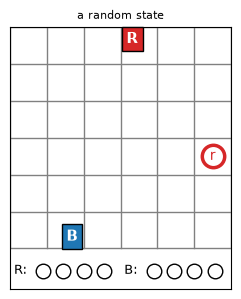

Blue's observation: [other agent, coin of my colour, coin of the other colour], centred on blue
[[[0. 0. 0. 0. 0. 0.]
  [0. 0. 1. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]]

 [[0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]]

 [[0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 1. 0.]
  [0. 0. 0. 0. 0. 0.]]]
lamps (red 1-4, blue 5-8): [0. 0. 0. 0. 0. 0. 0. 0.]


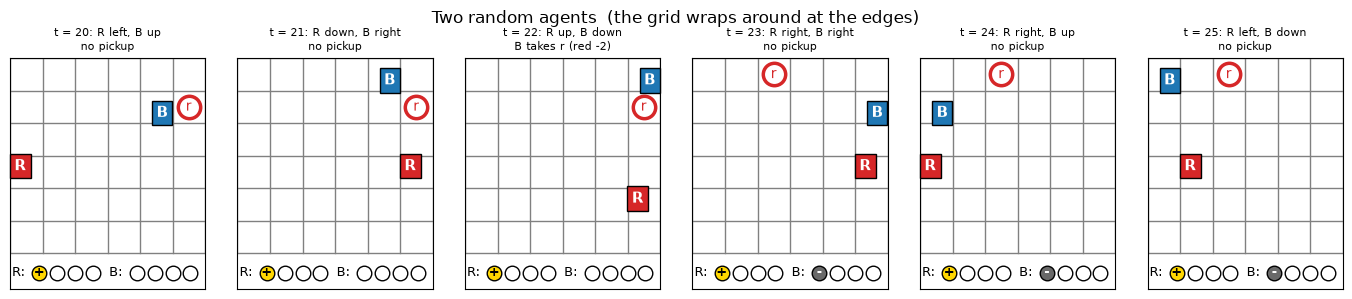

In [5]:
demo_env = CoinGame(n_envs=1, seed=SEED)
demo_env.reset()
fig, ax = plt.subplots(figsize=(3, 3.4))
draw_coin_game(demo_env, ax, title='a random state')
plt.show()

blue_observation = demo_env.observations()[BLUE][0]
grids = blue_observation[:3 * 36].reshape(3, GRID_SIZE, GRID_SIZE)
lamps = blue_observation[3 * 36:]
print("Blue's observation: [other agent, coin of my colour, coin of the other colour], centred on blue")
print(grids)
print('lamps (red 1-4, blue 5-8):', lamps)

show_episode([RandomPolicy(SEED), RandomPolicy(SEED + 1)], 'Two random agents', n_frames=6, skip_steps=20)

## 3.4 Rule agents (the Red agents of the development pool, and reference rules for Blue)

In [6]:
def read_observations(observations, grid_size=GRID_SIZE):
    """From one row of observations per game to positions in the egocentric grid (the agent itself is at cell 0).

    Returns my_cell, other_cell, coin_cell (int arrays), coin_is_mine (bool array) and the lamps,
    an array of shape (n, 2, HISTORY_LENGTH) with rows [red, blue].
    """
    n_cells = grid_size * grid_size
    grids = observations[:, :3 * n_cells].reshape(len(observations), 3, n_cells)
    my_cell = np.zeros(len(observations), dtype=int)
    other_cell = grids[:, 0].argmax(axis=1)
    coin_cell = (grids[:, 1] + grids[:, 2]).argmax(axis=1)
    coin_is_mine = grids[:, 1].sum(axis=1) > 0
    lamps = observations[:, 3 * n_cells:].reshape(len(observations), 2, HISTORY_LENGTH)
    return my_cell, other_cell, coin_cell, coin_is_mine, lamps


def next_cell(cells, actions, grid_size=GRID_SIZE):
    """The cells reached from `cells` with `actions`, on the torus."""
    row = (cells // grid_size + MOVES[actions, 0]) % grid_size
    column = (cells % grid_size + MOVES[actions, 1]) % grid_size
    return row * grid_size + column


def torus_step(start_cells, goal_cells, grid_size=GRID_SIZE):
    """One move from start towards goal along a shortest path on the torus (rows first, then columns)."""
    row_steps = (goal_cells // grid_size - start_cells // grid_size) % grid_size
    column_steps = (goal_cells % grid_size - start_cells % grid_size) % grid_size
    row_steps = np.where(row_steps > grid_size // 2, row_steps - grid_size, row_steps)
    column_steps = np.where(column_steps > grid_size // 2, column_steps - grid_size, column_steps)
    vertical_move = np.where(row_steps < 0, 0, 1)            # up or down
    horizontal_move = np.where(column_steps < 0, 2, 3)       # left or right
    return np.where(row_steps != 0, vertical_move, horizontal_move)


def torus_distance(cells_a, cells_b, grid_size=GRID_SIZE):
    """Number of moves between two cells on the torus."""
    row_steps = np.abs(cells_a // grid_size - cells_b // grid_size)
    column_steps = np.abs(cells_a % grid_size - cells_b % grid_size)
    return np.minimum(row_steps, grid_size - row_steps) + np.minimum(column_steps, grid_size - column_steps)


class GreedyAgent:
    """Goes for every coin, whatever its colour, along a shortest path."""

    def __init__(self, colour, seed=SEED):
        self.colour = colour
        self.rng = np.random.default_rng(seed)

    def act(self, observations):
        my_cell, other_cell, coin_cell, coin_is_mine, lamps = read_observations(observations)
        return torus_step(my_cell, coin_cell)


class AltruistAgent(GreedyAgent):
    """Goes only for its own coins; when the coin is the other's, it moves at random but never onto the coin."""

    def act(self, observations):
        my_cell, other_cell, coin_cell, coin_is_mine, lamps = read_observations(observations)
        towards_coin = torus_step(my_cell, coin_cell)
        wander = self.rng.integers(4, size=len(observations))
        for attempt in range(10):
            onto_coin = next_cell(my_cell, wander) == coin_cell
            wander[onto_coin] = self.rng.integers(4, size=onto_coin.sum())
        return np.where(coin_is_mine, towards_coin, wander)


class ReciprocatorAgent(AltruistAgent):
    """Altruist, unless the other agent took one of my coins in its last 4 pickups: then greedy.

    The decision is made again at every step from the other agent's 4 lamps, so the Reciprocator forgives: it is
    Altruist again as soon as the other's last 4 pickups contain no -1 (after 4 further pickups of its own colour).
    Forgiveness counts the other's pickups, not time: an agent that collects nothing stays "guilty" (the lamps carry
    over between episodes and are only cleared at the start of a match); every new defection restarts the punishment.
    """

    def act(self, observations):
        my_cell, other_cell, coin_cell, coin_is_mine, lamps = read_observations(observations)
        other_defected = (lamps[:, 1 - self.colour] == -1).any(axis=1)
        Altruist_actions = AltruistAgent.act(self, observations)
        greedy_actions = torus_step(my_cell, coin_cell)
        return np.where(other_defected, greedy_actions, Altruist_actions)


# Reference rules for Blue (Section 5.1). They are not learning agents: not allowed as a submission.
def make_greedy_blue(n_inputs, seed):
    return GreedyAgent(BLUE, seed)


def make_altruist_blue(n_inputs, seed):
    return AltruistAgent(BLUE, seed)

def make_random_blue(n_inputs, seed):
    return RandomPolicy(seed)

## 3.5 Learning agents: PPO, A2C and REINFORCE

`PPOAgent` is the PPO learner of Lab 2 (actor $\pi(a \mid s; \phi)$ and critic $V(s; \theta)$, clipped actor loss, entropy regularization), with one change: the discount factor is $\gamma = 0.99$ instead of $0.95$, because with a history that carries over between episodes the effect of a coin taken now can show up many steps later. The same class gives two other policy-gradient algorithms by switching parts of PPO off:

| algorithm | configuration | what it lacks compared with PPO |
|---|---|---|
| **PPO** | `PPO_CONFIG` (critic, clipping, 4 epochs of 4 minibatches per update) | |
| **A2C** | `A2C_CONFIG`: `clip=None, n_epochs=1, n_minibatches=1` | no data reuse, no trust region |
| **REINFORCE** | `REINFORCE_CONFIG`: as A2C, and `use_critic=False` | no critic: Monte Carlo returns, no bootstrapping at the end of the episode |

(In all three, `normalize_advantages=True` subtracts the batch mean of the advantages, which acts as a simple baseline.)

In [7]:
def make_network(n_inputs, n_outputs, hidden=64):
    """A small multilayer perceptron with two hidden layers of `hidden` units (tanh)."""
    return nn.Sequential(nn.Linear(n_inputs, hidden), nn.Tanh(),
                         nn.Linear(hidden, hidden), nn.Tanh(),
                         nn.Linear(hidden, n_outputs))


def compute_advantages(rewards, values, last_values, gamma, gae_lambda):
    """Advantages Adv(s_t, a_t) and critic targets y_t for one batch of data (generalised advantage estimation).

    rewards, values: arrays of shape (n_steps, n_envs); last_values: V(s; theta) of the state after the last step.
    gae_lambda = 0: one-step estimate r_t + gamma V(s_t+1) - V(s_t); gae_lambda = 1: Monte Carlo estimate u_t - V(s_t).
    """
    n_steps = len(rewards)
    advantages = np.zeros_like(rewards)
    next_values = last_values
    next_advantage = np.zeros_like(last_values)
    for t in reversed(range(n_steps)):
        one_step_advantage = rewards[t] + gamma * next_values - values[t]
        next_advantage = one_step_advantage + gamma * gae_lambda * next_advantage
        advantages[t] = next_advantage
        next_values = values[t]
    critic_targets = advantages + values          # y_t
    return advantages, critic_targets


def ppo_actor_loss(log_probs, behaviour_log_probs, advantages, clip):
    """Clipped PPO actor loss: -mean(min(rho * Adv, clip(rho, 1 - clip, 1 + clip) * Adv)); clip=None: no clipping."""
    importance_weights = torch.exp(log_probs - behaviour_log_probs)        # rho = pi(a|s; phi) / pi_beta(a|s)
    objective = importance_weights * advantages
    if clip is not None:
        clipped_weights = torch.clamp(importance_weights, 1 - clip, 1 + clip)
        objective = torch.min(objective, clipped_weights * advantages)
    return -objective.mean()

In [8]:
PPO_CONFIG = dict(
    lr=3e-3,                    # learning rate of Adam (actor and critic)
    gamma=0.99,                 # discount factor (Lab 2: 0.95)
    gae_lambda=0.95,            # advantage estimate: 0 = one-step, 1 = Monte Carlo
    clip=0.2,                   # clipping parameter epsilon of the importance sampling weight (None = no clipping)
    n_epochs=4,                 # epochs N_e: updates on the same batch of data
    n_minibatches=4,            # minibatches per epoch
    entropy_coef=0.01,          # weight c_e of the entropy regularization
    value_coef=0.5,             # weight c_v of the critic loss
    normalize_advantages=True,  # rescale the advantages of a batch to mean 0 and standard deviation 1
    use_critic=True,            # False: no critic; the advantage is the Monte Carlo return u_t (REINFORCE)
    hidden=64,                  # units per hidden layer
    max_grad_norm=0.5,          # gradient clipping (a safety net against very large steps)
)


def ppo_update(agent, observations, actions, behaviour_log_probs, advantages, critic_targets):
    """One PPO update from a batch of data (one row per decision). Returns the approximate KL divergence of the update."""
    config = agent.config
    observations = torch.as_tensor(observations, dtype=torch.float32)
    actions = torch.as_tensor(actions)
    behaviour_log_probs = torch.as_tensor(behaviour_log_probs, dtype=torch.float32)
    advantages = torch.as_tensor(advantages, dtype=torch.float32)
    critic_targets = torch.as_tensor(critic_targets, dtype=torch.float32)
    if config['normalize_advantages']:
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    n_samples = len(actions)
    for epoch in range(config['n_epochs']):
        shuffled = agent.rng.permutation(n_samples)
        for minibatch in np.array_split(shuffled, config['n_minibatches']):
            policy = Categorical(logits=agent.actor(observations[minibatch]))
            log_probs = policy.log_prob(actions[minibatch])
            actor_loss = ppo_actor_loss(log_probs, behaviour_log_probs[minibatch], advantages[minibatch], config['clip'])
            entropy = policy.entropy().mean()
            loss = actor_loss - config['entropy_coef'] * entropy
            if config['use_critic']:
                values = agent.critic(observations[minibatch]).squeeze(-1)
                critic_loss = ((critic_targets[minibatch] - values) ** 2).mean()
                loss = loss + config['value_coef'] * critic_loss
            agent.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters, config['max_grad_norm'])
            agent.optimizer.step()

    # Size of the update: approximate KL divergence between the behaviour policy and the updated policy
    with torch.no_grad():
        log_weights = Categorical(logits=agent.actor(observations)).log_prob(actions) - behaviour_log_probs
        approx_kl = ((torch.exp(log_weights) - 1) - log_weights).mean().item()
    return approx_kl

In [9]:
class PPOAgent:
    """The PPO learner of Lab 2 (also A2C and REINFORCE, through its configuration).

    PPOAgent(n_inputs, n_actions, config=None, seed=SEED): config is a dict of settings that replace those of
    PPO_CONFIG (e.g. A2C_CONFIG, or dict(PPO_CONFIG, lr=1e-3)).
    act(observations, greedy=False) -> actions; record(observations, actions, rewards, next_observations) stores one
    step; end_of_episode(last_observations) learns from the stored episode and clears it (on-policy).
    """

    def __init__(self, n_inputs, n_actions, config=None, seed=SEED):
        self.config = dict(PPO_CONFIG, **(config or {}))
        torch.manual_seed(seed)
        self.rng = np.random.default_rng(seed)
        self.actor = make_network(n_inputs, n_actions, self.config['hidden'])
        self.critic = make_network(n_inputs, 1, self.config['hidden'])
        self.parameters = list(self.actor.parameters()) + list(self.critic.parameters())
        self.optimizer = torch.optim.Adam(self.parameters, lr=self.config['lr'])
        self.buffer = {'observations': [], 'actions': [], 'log_probs': [], 'values': [], 'rewards': []}
        self.update_sizes = []          # approximate KL divergence of every update

    def act(self, observations, greedy=False):
        """Sample one action per game from the policy (greedy=True: the most likely action)."""
        with torch.no_grad():
            policy = Categorical(logits=self.actor(torch.as_tensor(observations, dtype=torch.float32)))
            actions = policy.probs.argmax(dim=-1) if greedy else policy.sample()
            # Remembered for record(): log pi_beta(a|s), the log-probability under the behaviour policy
            self.last_log_probs = policy.log_prob(actions).numpy()
        return actions.numpy()

    def value(self, observations):
        """The critic's estimate V(s; theta) (zeros without a critic)."""
        if not self.config['use_critic']:
            return np.zeros(len(observations), dtype=np.float32)       # no learned baseline
        with torch.no_grad():
            return self.critic(torch.as_tensor(observations, dtype=torch.float32)).squeeze(-1).numpy()

    def record(self, observations, actions, rewards, next_observations):
        """Store one step of every game; `rewards` is the learning signal (the training reward)."""
        self.buffer['observations'].append(observations)
        self.buffer['actions'].append(actions)
        self.buffer['log_probs'].append(self.last_log_probs)
        self.buffer['values'].append(self.value(observations))
        self.buffer['rewards'].append(np.asarray(rewards, dtype=np.float32))

    def end_of_episode(self, last_observations):
        """Learn from the data just collected, then throw it away (PPO is on-policy)."""
        rollout = {key: np.array(values) for key, values in self.buffer.items()}     # shapes (n_steps, n_envs, ...)
        # The episode is cut after a fixed number of steps, not over: we bootstrap from the value of the last observation.
        # Without a critic, V = 0 and lambda = 1: the advantage is the Monte Carlo return u_t (REINFORCE).
        gae_lambda = self.config['gae_lambda'] if self.config['use_critic'] else 1.0
        advantages, critic_targets = compute_advantages(rollout['rewards'], rollout['values'], self.value(last_observations),
                                                 self.config['gamma'], gae_lambda)
        n_inputs = rollout['observations'].shape[-1]
        approx_kl = ppo_update(self, rollout['observations'].reshape(-1, n_inputs), rollout['actions'].reshape(-1),
                               rollout['log_probs'].reshape(-1), advantages.reshape(-1), critic_targets.reshape(-1))
        self.update_sizes.append(approx_kl)
        self.buffer = {key: [] for key in self.buffer}


# A2C and REINFORCE: the same agent with parts of PPO switched off
A2C_CONFIG = dict(PPO_CONFIG, clip=None, n_epochs=1, n_minibatches=1)
REINFORCE_CONFIG = dict(A2C_CONFIG, use_critic=False)


def welfare_reward(my_reward, other_reward, observations):
    """A training reward: learn from the social welfare (own reward + the other agent's reward)."""
    return my_reward + other_reward


def make_learner(config, training_reward=own_reward):
    """Returns a function make(n_inputs, seed) that creates a fresh PPOAgent with this config and training reward."""
    def make(n_inputs, seed):
        agent = PPOAgent(n_inputs, 4, config=config, seed=seed)
        agent.training_reward = training_reward
        return agent
    return make


# The development pool: one function per Red agent, make(n_inputs, seed) -> a fresh Red agent
def make_greedy_red(n_inputs, seed):
    return GreedyAgent(RED, seed)


def make_altruist_red(n_inputs, seed):
    return AltruistAgent(RED, seed)


def make_reciprocator_red(n_inputs, seed):
    return ReciprocatorAgent(RED, seed)


def make_random_red(n_inputs, seed):
    return RandomPolicy(seed)


DEV_POOL = {'Greedy': make_greedy_red, 'Altruist': make_altruist_red, 'Reciprocator': make_reciprocator_red,
            'Random': make_random_red, 'PPO': make_learner(PPO_CONFIG, own_reward)}

## 3.6 Matches and evaluation

In [10]:
MEASURES = ['welfare', 'reward_red', 'reward_blue', 'own_share_red', 'own_share_blue', 'coins']


def play_match(make_red, make_blue, seed=SEED, n_updates=MATCH_UPDATES, n_envs=N_ENVS, game=CoinGame):
    """One match between a fresh red and a fresh blue (both created with make(n_inputs, seed)).

    Plays n_updates updates (one episode in each of n_envs games each); learners learn during the match.
    Returns (log, red, blue): log = {statistic: array with one value per update} (the statistics of play_episode),
    and the two agents at the end of the match. `game` is the class of the environment.
    """
    env = game(n_envs, seed=seed)
    red = make_red(env.n_inputs, seed + 1)
    blue = make_blue(env.n_inputs, seed + 2)
    log = {}
    for update in range(n_updates):
        stats = play_episode(env, [red, blue])
        for key, value in stats.items():
            log.setdefault(key, []).append(value)
    log = {key: np.array(values) for key, values in log.items()}
    return log, red, blue


def match_score(log, last=SCORE_UPDATES):
    """The scores of a match: the average of every measure over the last `last` updates."""
    return {key: log[key][-last:].mean() for key in MEASURES}


def evaluate_against_pool(make_blue, pool=DEV_POOL, seeds=(SEED,)):
    """One match against every red of `pool` for every seed.

    Returns (results, logs): results = {red name: {measure: array with one value per seed}},
    logs = {red name: [log of every seed]}.
    """
    results, logs = {}, {}
    for red_name, make_red in pool.items():
        scores = []
        logs[red_name] = []
        for seed in seeds:
            log, red, blue = play_match(make_red, make_blue, seed=seed)
            scores.append(match_score(log))
            logs[red_name].append(log)
        results[red_name] = {key: np.array([score[key] for score in scores]) for key in MEASURES}
    return results, logs


def print_results(results, title=''):
    """A table with one row per red agent (mean +- sd over seeds) and the pool averages of both scores."""
    print(title)
    print(f'{"red agent":14s} {"welfare":>15s} {"reward red":>11s} {"reward blue":>12s} '
          f'{"red restraint":>14s} {"blue restraint":>15s} {"pickups":>8s}')
    for red_name, result in results.items():
        welfare = result['welfare']
        print(f'{red_name:14s} {welfare.mean():+8.2f} +- {welfare.std():4.2f} {result["reward_red"].mean():+11.2f} '
              f'{result["reward_blue"].mean():+12.2f} {result["own_share_red"].mean():14.2f} '
              f'{result["own_share_blue"].mean():15.2f} {result["coins"].mean():8.1f}')
    pool_welfare = np.mean([result['welfare'].mean() for result in results.values()])
    pool_reward_blue = np.mean([result['reward_blue'].mean() for result in results.values()])
    print(f'{"pool average":14s} {pool_welfare:+8.2f}{"":20s}{pool_reward_blue:+12.2f}   (welfare, reward blue)\n')


def plot_match(runs, title, window=10):
    """Curves of matches. runs = {label: log}; moving averages over `window` updates."""
    panels = [('coins', 'pickups per episode', 'individual performance'),
              ('own_share_red', 'own-colour share of red', 'restraint of red'),
              ('own_share_blue', 'own-colour share of blue', 'restraint of blue'),
              ('welfare', 'reward red + reward blue', 'welfare')]
    line_styles = ['-', '--', '-.', ':']
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    for k, (label, log) in enumerate(runs.items()):
        for ax, (key, ylabel, panel_title) in zip(axes, panels):
            smooth = np.convolve(log[key], np.ones(window) / window, mode='valid')
            ax.plot(smooth, linestyle=line_styles[k % len(line_styles)], linewidth=2, label=label)
            ax.set_ylabel(ylabel)
            ax.set_title(panel_title)
            ax.set_xlabel(f'update ({N_ENVS} episodes each)')
    for ax in axes[1:3]:
        ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    axes[3].axhline(0, color='gray', linewidth=1)
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def pool_scores(results, measure):
    """Pool average of `measure` for every seed: the average over the red agents, one value per seed."""
    per_red = np.array([result[measure] for result in results.values()])      # shape (n_reds, n_seeds)
    return per_red.mean(axis=0)


def plot_pareto(results_by_blue, title):
    """Pareto plot. results_by_blue = {label: results of evaluate_against_pool}.

    One point per blue agent at (pool-average welfare, pool-average reward of blue), +- sd over seeds.
    """
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    for k, (label, results) in enumerate(results_by_blue.items()):
        welfare = pool_scores(results, 'welfare')
        own_reward = pool_scores(results, 'reward_blue')
        ax.errorbar(welfare.mean(), own_reward.mean(), xerr=welfare.std(), yerr=own_reward.std(),
                    marker=markers[k % len(markers)], markersize=9, capsize=3, linestyle='none', label=label)
        ax.annotate(label, (welfare.mean(), own_reward.mean()), textcoords='offset points', xytext=(6, 6), fontsize=8)
    ax.set_xlabel('welfare per episode (pool average)')
    ax.set_ylabel("blue's own reward per episode (pool average)")
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 3.7 Evaluation

In [11]:
def reciprocity_curve(red, blue, n_games=256, n_episodes=4, seed=SEED + 99):
    """How often blue takes a red coin it can reach in one move, by the number of -1 lamps in red's history.

    red, blue: the agents of a finished match; they play new games without learning.
    Returns (probability, chances): two arrays of length HISTORY_LENGTH + 1 (0 to 4 defections of red).
    """
    env = CoinGame(n_games, seed=seed)
    chances = np.zeros(HISTORY_LENGTH + 1)
    takes = np.zeros(HISTORY_LENGTH + 1)
    for episode in range(n_episodes):
        observations = env.reset()
        for t in range(env.episode_length):
            red_defections = (env.history[:, RED] == -1).sum(axis=1)
            can_take_red_coin = (env.coin_colour == RED) & (torus_distance(env.agent_cells[BLUE], env.coin_cell) == 1)
            actions = [red.act(observations[RED]), blue.act(observations[BLUE])]
            observations, rewards, info = env.step(actions)
            took_it = info['picked'][BLUE] & can_take_red_coin
            np.add.at(chances, red_defections[can_take_red_coin], 1)
            np.add.at(takes, red_defections[can_take_red_coin], took_it[can_take_red_coin])
    return takes / np.maximum(chances, 1), chances


def plot_reciprocity_curves(curves, title):
    """curves = {label: output of reciprocity_curve}; points with fewer than 20 chances are not shown."""
    fig, ax = plt.subplots(figsize=(6, 3.5))
    markers = ['o', 's', '^', 'D']
    for k, (label, (probability, chances)) in enumerate(curves.items()):
        observed = chances >= 20
        defections = np.arange(HISTORY_LENGTH + 1)
        ax.plot(defections[observed], probability[observed], marker=markers[k % 4], linewidth=2, label=label)
    ax.set_xlabel("number of -1 lamps in red's history")
    ax.set_ylabel('P(blue takes a reachable red coin)')
    ax.set_xticks(range(HISTORY_LENGTH + 1))
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


class LampAblation:
    """Wraps a learning agent: it sees observations with all lamps set to 0. Its training reward sees the real ones."""

    def __init__(self, agent):
        self.agent = agent
        self.training_reward = getattr(agent, 'training_reward', own_reward)

    def without_lamps(self, observations):
        blind = observations.copy()
        blind[:, -2 * HISTORY_LENGTH:] = 0.0
        return blind

    def act(self, observations):
        return self.agent.act(self.without_lamps(observations))

    def record(self, observations, actions, rewards, next_observations):
        self.agent.record(self.without_lamps(observations), actions, rewards, self.without_lamps(next_observations))

    def end_of_episode(self, last_observations):
        self.agent.end_of_episode(self.without_lamps(last_observations))


def make_lamp_ablation(make_blue):
    """The same learner, blind to the lamps: returns make(n_inputs, seed)."""
    def make(n_inputs, seed):
        return LampAblation(make_blue(n_inputs, seed))
    return make


def foreign_pickups_by_step(log, last=SCORE_UPDATES):
    """Red coins taken by blue at each step of the episode, averaged over the last `last` updates of a match."""
    return log['blue_takes_red_by_step'][-last:].mean(axis=0)

# 4. What your agent must provide

## 4.1 Defining the agent's program

In Section 5.2 you define one function:

```python
def make_blue_agent(n_inputs, seed):
    ...
    return agent          # a fresh, untrained learning agent
```

This function called at the start of **every match** (`n_inputs = 116`; `seed` differs per match), and must return a **new** agent that has not learned anything yet. The agent must have these methods; this is how the environment interacts with the agent (see `play_episode` in Section 3.2):

| method | called | receives | returns |
|---|---|---|---|
| `act(observations)` | at every step | float32 array `(n_games, 116)`: Blue's observations in every game | int array `(n_games,)` of actions in {0 = up, 1 = down, 2 = left, 3 = right} |
| `training_reward(my_reward, other_reward, observations)` *(optional; default: `own_reward`)* | after every step | Blue's and Red's environment rewards, arrays `(n_games,)`, and Blue's observations *before* the step | the learning signal, array `(n_games,)` |
| `record(observations, actions, rewards, next_observations)` | after every step | the step, with `rewards` = the output of `training_reward` | nothing |
| `end_of_episode(last_observations)` | after the last step of an episode (every 48 steps) | Blue's last observations | nothing; this is where the agent learns |

One update of a match, as `play_episode` runs it:

```python
observations = env.reset()                                    # the lamps are kept from the previous episode
for t in range(48):
    actions = [red.act(observations[RED]), blue.act(observations[BLUE])]
    next_observations, rewards, info = env.step(actions)
    signal = blue.training_reward(rewards[BLUE], rewards[RED], observations[BLUE])
    blue.record(observations[BLUE], actions[BLUE], signal, next_observations[BLUE])
    observations = next_observations
blue.end_of_episode(observations[BLUE])
```

## 4.2 Blue's observation

| indices | content |
|---|---|
| 0-35 | the **other agent** (Red): a one-hot $6 \times 6$ grid, centred on Blue (Blue is at row 0, column 0; the other cells are counted from there, wrapping around) |
| 36-71 | the **coin, if it is blue** (one-hot grid; all zeros if the coin is red) |
| 72-107 | the **coin, if it is red** (one-hot grid; all zeros if the coin is blue) |
| 108-111 | **Red's last 4 pickups**, most recent first: +1 red coin, -1 blue coin, 0 no pickup yet |
| 112-115 | **Blue's last 4 pickups**, most recent first: +1 blue coin, -1 red coin, 0 no pickup yet |

For example, `observations[:, 108:112]` are Red's lamps and `(observations[:, 108:112] == -1).any(axis=1)` tells, per game, whether Red took one of Blue's coins in its last 4 pickups.

## 4.3 Building your agent

* **Start from `PPOAgent` and customize** (Section 3.5). `PPOAgent(n_inputs, 4, config=..., seed=seed)` with `PPO_CONFIG`, `A2C_CONFIG` or `REINFORCE_CONFIG`, or your own variant, e.g. `dict(PPO_CONFIG, lr=1e-3, entropy_coef=0.02)`. Every setting is explained in `PPO_CONFIG`.
* **Choose a training reward** by setting `agent.training_reward` to a function with the signature above. `own_reward` and `welfare_reward` are given; using any of these with a justification or designing your own is part of the assignment.

## 4.4 Evaluating your agent

| function | use |
|---|---|
| `evaluate_against_pool(make_blue_agent, seeds=(SEED, SEED + 1, SEED + 2))` | one match against every Red of `DEV_POOL` per seed; returns `(results, logs)` |
| `print_results(results, title)` | table per Red agent and pool averages of both scores |
| `plot_pareto({label: results, ...}, title)` | compare agents on both scores |
| `play_match(make_red, make_blue_agent, seed)` | one match; returns `(log, red, blue)` with the agents at the end of the match |
| `plot_match({label: log, ...}, title)` | the course of matches: pickups, restraint of both agents, welfare |
| `reciprocity_curve(red, blue)`, `plot_reciprocity_curves` | does Blue respond to Red's history? Use a Red that actually defects (e.g. `DEV_POOL['Greedy']` or `DEV_POOL['PPO']`), else there are no observations with -1 lamps |
| `make_lamp_ablation(make_blue_agent)` | the same agent blind to the lamps: does your agent use them? |
| `foreign_pickups_by_step(log)` | when in an episode does Blue take red coins? |
| `show_episode([red, blue], title)` | watch a few steps of trained agents |

One match takes 5-40 seconds; the development pool with one seed takes about 2 minutes, with 5 seeds about ~10 minutes.

# 5. Your assignment

## 5.1 Reference results

The goal is developing Agents that perform well according to an individual and collective score. Of course, there are trivial solutions. The **Greedy** and **Altruist** rule-based agents should perform well in the individual score and social welfare, respectivelly. A random agent should be Pareto dominated by more sophisticated agents. Note that these simple agent programs are intended to test your solution against, and they do not count as valid submissions as these are not learning agents. Below an example of evaluation of these 3 simple agents against the pool of Red agents. 

Blue = Greedy
red agent              welfare  reward red  reward blue  red restraint  blue restraint  pickups
Greedy            -0.10 +- 0.00       -0.25        +0.15           0.50            0.49     23.6
Altruist          +8.64 +- 0.00       -4.92       +13.56           1.00            0.62     18.9
Reciprocator      +0.62 +- 0.00       -0.13        +0.75           0.52            0.51     23.6
Random            -0.02 +- 0.00      -13.86       +13.85           0.49            0.50     16.2
PPO               +0.74 +- 0.00       -2.05        +2.79           0.52            0.51     22.3
pool average      +1.98                           +6.22   (welfare, reward blue)

Blue = Altruist
red agent              welfare  reward red  reward blue  red restraint  blue restraint  pickups
Greedy            +8.37 +- 0.00      +13.63        -5.26           0.61            1.00     19.0
Altruist         +15.26 +- 0.00       +7.47        +7.79           1.00            1.00     15.3
Reciprocator     

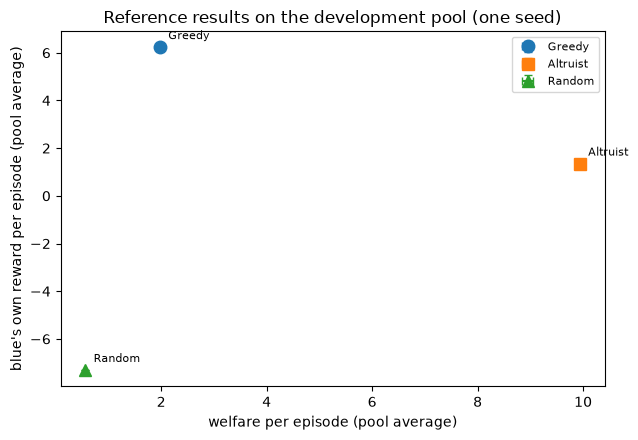

In [12]:
baseline_results, baseline_logs = {}, {}
for name, make_blue in [('Greedy', make_greedy_blue), ('Altruist', make_altruist_blue), ('Random', make_random_blue)]:
    baseline_results[name], baseline_logs[name] = evaluate_against_pool(make_blue)
    print_results(baseline_results[name], f'Blue = {name}')

plot_pareto(baseline_results, 'Reference results on the development pool (one seed)')

## 5.2 Your agent

Define your agent in the cell below. It **must start with the line `# YOUR AGENT`**: this is the cell we run when we evaluate your submission, on top of the code of Sections 3 and 4 (so it may use everything defined there, except the rule helpers and the Red agents). Keep your final agent in this single cell. The template is the PPO reference on its own reward.

In [13]:
# YOUR AGENT


SILLY_CONFIG = dict(PPO_CONFIG, max_grad_norm=0.01) # just for example purposes, silly configuration file, why?

def my_training_reward(my_reward, other_reward, observations):
    # The learning signal of blue (one value per game). observations: blue's observations before the step,
    # the last 8 numbers are the lamps (red's last 4 pickups, then blue's).
    return other_reward # just for example purposes, not super interesting utility function, why?


def make_blue_agent(n_inputs, seed):
    agent = PPOAgent(n_inputs, 4, config=SILLY_CONFIG, seed=seed)
    agent.training_reward = my_training_reward
    return agent

## 5.3 Evaluate your agent

Against the development pool, compared with the reference results (one seed: about 2 minutes; use at least 3 seeds for your report).

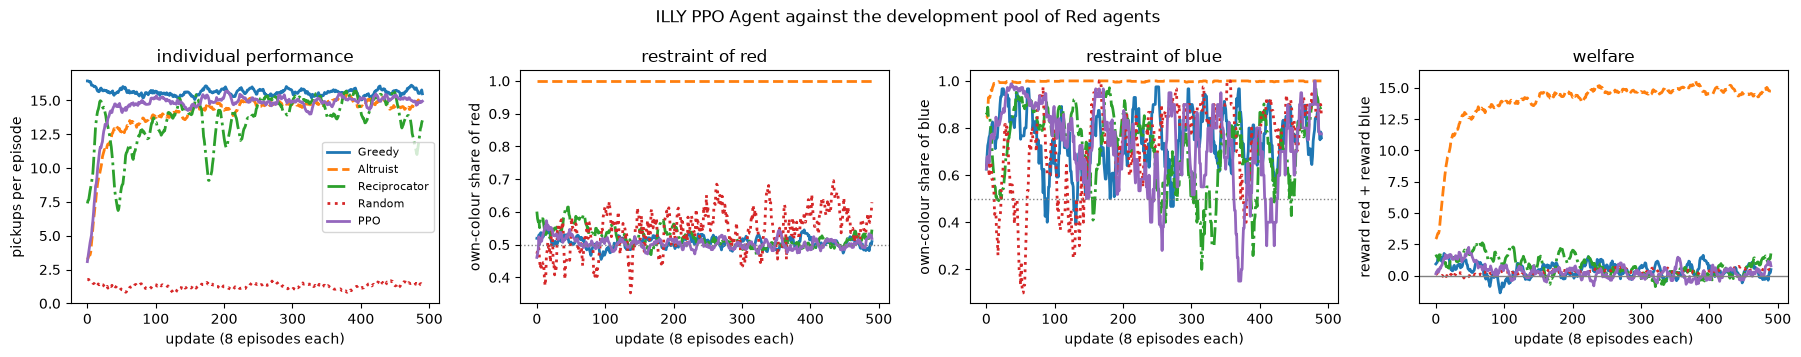

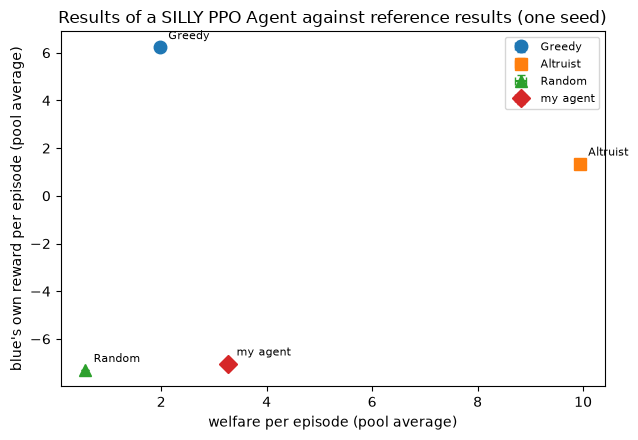

In [14]:
my_results, my_logs = evaluate_against_pool(make_blue_agent, seeds=(SEED,))
plot_match({red_name: logs[0] for red_name, logs in my_logs.items()}, 'ILLY PPO Agent against the development pool of Red agents')
plot_pareto({**baseline_results, 'my agent': my_results}, 'Results of a SILLY PPO Agent against reference results (one seed)')

## 5.4 Your experiments

Add your experiments below.

Do not forget to add the comparison of your candidate agents, the tests of your hypotheses, the evaluation with at least 3-5 seeds and some interpretation of the obtained results.

Also, please make sure to:

* **Register your hypotheses.** Write them in your report, with a date. Do not edit them afterwards; add new ones, with a new date, if your plans change. A wrong hypothesis that you analyse honestly is worth more than a right one written after the fact.
* **Name your experiment cells.** Start every experiment cell with a comment that names it, e.g. `# exp_lr_sweep: PPO with three learning rates, 3 seeds`, and refer to that name in the caption of every table and figure of your report.
* **Keep an experiment log for you.** One dated line per experiment (what you tried, what happened, including failures).

**Before you submit:** the notebook runs from top to bottom in a fresh kernel ("Restart & Run All") without errors, and your agent is in the single cell starting with `# YOUR AGENT`.

In [15]:
# Your experiments